# Д/з №1. Data Detective - Quality Control at the Factory

## 0. Авторизация Kaggle и выгрузка датасета

In [86]:
%pip install -q kaggle

In [87]:
import os
from getpass import getpass

os.environ["KAGGLE_API_TOKEN"] = getpass("Kaggle API Token: ")

In [88]:
!kaggle competitions download -c data-detective-quality-control-at-the-factory
!unzip -o data-detective-quality-control-at-the-factory.zip -d data

data-detective-quality-control-at-the-factory.zip: Skipping, found more recently modified local copy (use --force to force download)
Archive:  data-detective-quality-control-at-the-factory.zip
  inflating: data/sample_submission.csv  
  inflating: data/test.csv           
  inflating: data/train.csv          


In [89]:
# Отобразим, какие данные мы выгрузили
print(os.listdir("data"))

['train.csv', 'sample_submission.csv', 'test.csv']


### 1. Импорты и настройки

In [90]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
plt.rcParams["figure.dpi"] = 100
RANDOM_STATE = 42

### 2. Загрузка данных

In [91]:
train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")

print("train:", train.shape, "  test:", test.shape)

train: (4025, 19)   test: (1500, 18)


### 3. EDA и предобработка данных

In [92]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4025 entries, 0 to 4024
Data columns (total 19 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id            4025 non-null   int64  
 1   sensor_a      4025 non-null   float64
 2   sensor_b      4025 non-null   float64
 3   temperature   4025 non-null   float64
 4   vibration     4025 non-null   float64
 5   line_id       4025 non-null   int64  
 6   pressure_bar  4025 non-null   float64
 7   pressure_psi  4025 non-null   float64
 8   pressure_pa   4025 non-null   float64
 9   photo_lux     4025 non-null   float64
 10  aux_0         4025 non-null   float64
 11  aux_1         4025 non-null   float64
 12  aux_2         4025 non-null   float64
 13  aux_3         4025 non-null   float64
 14  aux_4         4025 non-null   float64
 15  aux_5         4025 non-null   float64
 16  aux_6         4025 non-null   float64
 17  aux_7         4025 non-null   float64
 18  defect        4025 non-null 

In [93]:
train.describe()

,id,sensor_a,sensor_b,temperature,vibration,line_id,pressure_bar,pressure_psi,pressure_pa,photo_lux,aux_0,aux_1,aux_2,aux_3,aux_4,aux_5,aux_6,aux_7,defect
count,4025.000000,4025.000000,4025.000000,4025.000000,4025.000000,4025.000000,4025.000000,4025.00000,4025.000000,4025.000000,4025.000000,4025.000000,4025.000000,4025.000000,4025.000000,4025.000000,4025.000000,4025.000000,4025.000000
mean,2012.000000,-0.016347,0.011151,-101.338012,18.125441,6.555528,5.123456,74.30960,512345.590062,367.411056,-0.669506,-0.072879,0.088949,-0.172909,-0.046377,-0.388042,-0.026846,0.085758,0.303106
std,1162.061745,2.043337,2.052522,382.805506,57.696136,3.456986,1.032568,14.97608,103256.814485,106.621239,18.444236,2.383378,17.336286,6.283050,15.194897,17.155456,2.051726,5.121916,0.459658
min,0.000000,-6.635200,-6.042800,-999.000000,0.017000,1.000000,1.536000,22.27000,153600.000000,202.900000,-65.394000,-9.052000,-67.652000,-21.374000,-60.224000,-58.565000,-7.100000,-16.736000,0.000000
25%,1006.000000,-1.559900,-1.524500,51.500000,1.501000,3.000000,4.402000,63.85000,440200.000000,289.800000,-12.902000,-1.667000,-11.425000,-4.419000,-9.940000,-12.327000,-1.376000,-3.491000,0.000000
50%,2012.000000,-0.029800,-0.002000,59.800000,4.385000,7.000000,5.117000,74.22000,511700.000000,317.800000,-0.761000,-0.084000,-0.060000,-0.229000,-0.219000,-0.229000,-0.045000,0.040000,0.000000
75%,3018.000000,1.530100,1.573000,66.200000,14.061000,10.000000,5.819000,84.39000,581900.000000,482.400000,11.598000,1.530000,11.834000,4.010000,9.699000,11.325000,1.320000,3.620000,1.000000
max,4024.000000,6.325500,5.910900,87.000000,1485.473000,12.000000,8.683000,125.93000,868300.000000,646.700000,78.650000,11.953000,72.542000,22.731000,57.503000,71.651000,7.318000,17.628000,1.000000


In [94]:
# Пропуски как NaN
print("Пропусков (NaN) по столбцам:")
print(train.isna().sum())

Пропусков (NaN) по столбцам:
id              0
sensor_a        0
sensor_b        0
temperature     0
vibration       0
line_id         0
pressure_bar    0
pressure_psi    0
pressure_pa     0
photo_lux       0
aux_0           0
aux_1           0
aux_2           0
aux_3           0
aux_4           0
aux_5           0
aux_6           0
aux_7           0
defect          0
dtype: int64


In [95]:
# Дубликаты в train. Важно: исключаем 'id' и 'defect' из проверки
feature_cols = [c for c in train.columns if c not in ("id", "defect")]
n_dup = train.duplicated(subset=feature_cols).sum()
print(f"Дубликатов строк (по признакам): {n_dup}") # <-- Проблема №1

Дубликатов строк (по признакам): 525


Найдена **Проблема №1** – дубликаты строк. В реальности при таком количестве параметров наличие даже двух дубликатов маловероятно. А у нас их 525 шт.

In [96]:
# Удалим дубликаты
import copy

train_old = copy.deepcopy(train)
train = train_old.drop_duplicates(subset=feature_cols).reset_index(drop=True)

Посмотрим на распределение признаков.

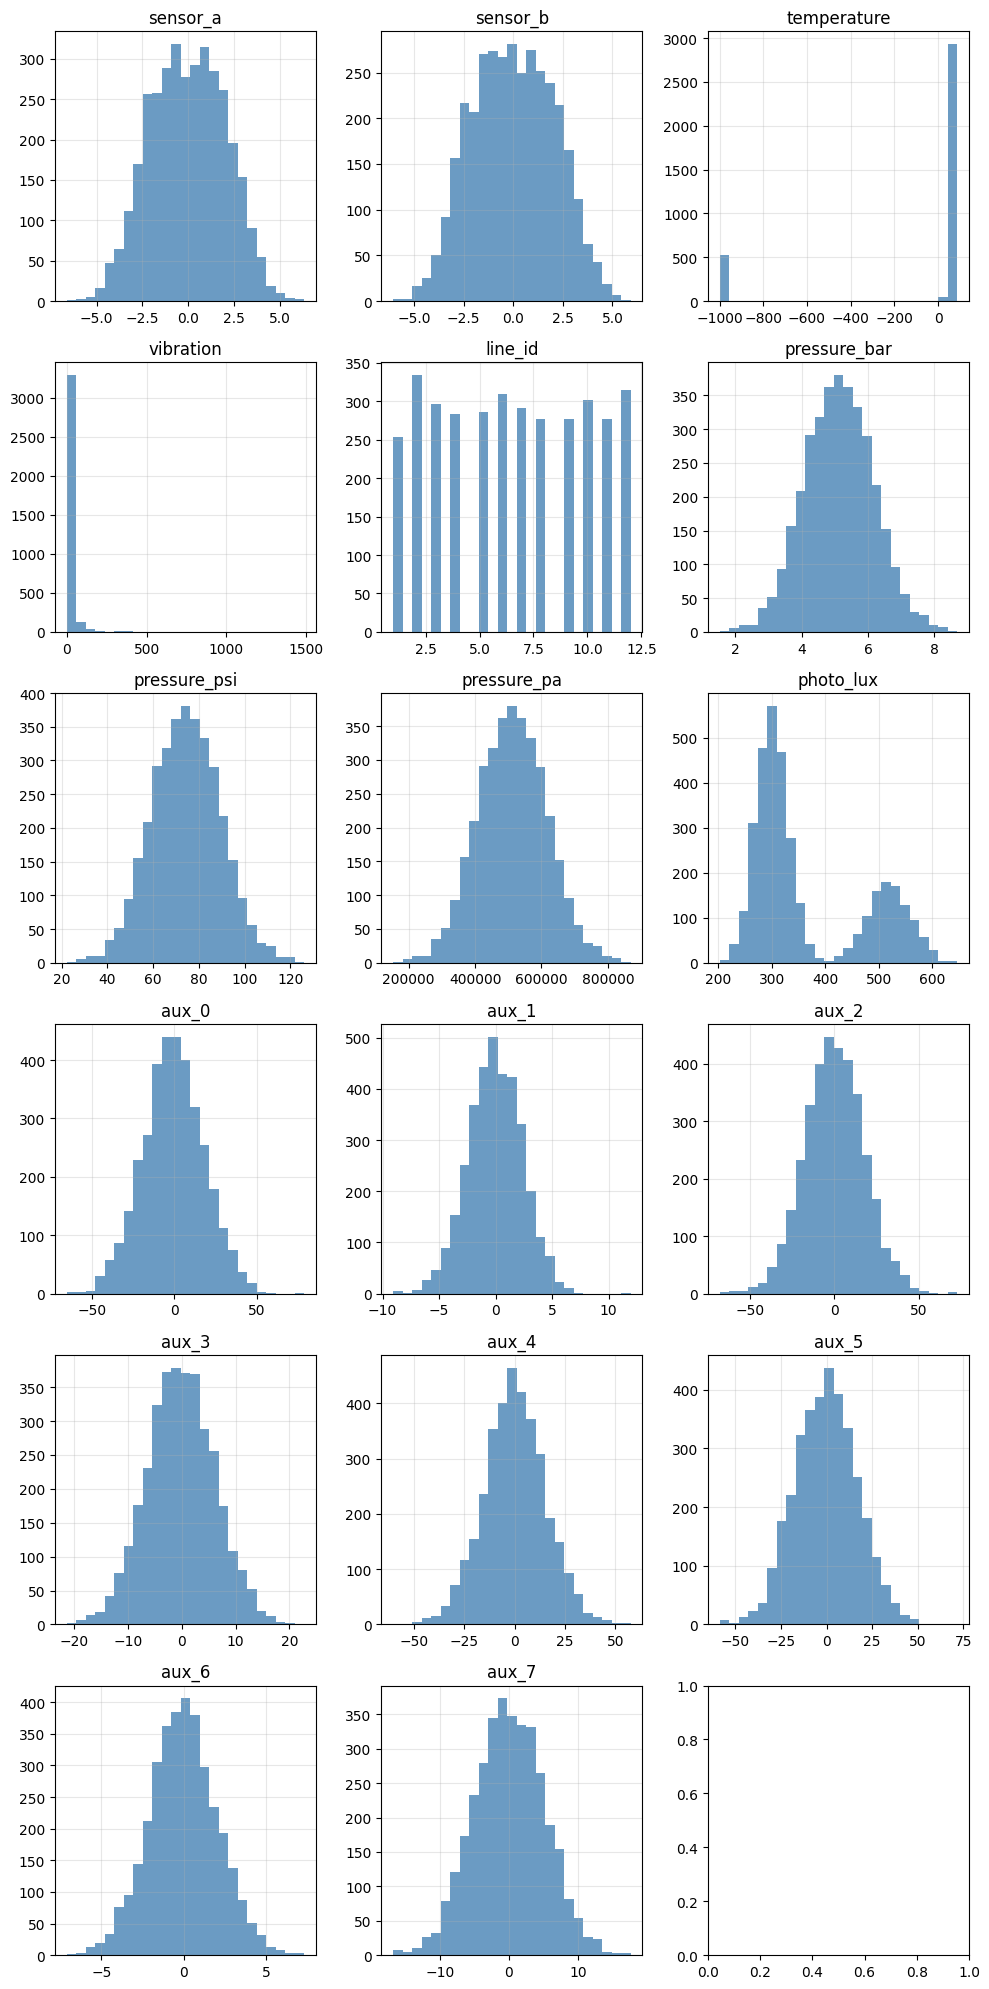

In [97]:
fig, axes = plt.subplots(6, 3, figsize=(10, 20))
for ax, col in zip(axes.flat, feature_cols):
    ax.hist(train[col], bins=25, color="steelblue", alpha=0.8)
    ax.set_title(col)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Найдена **Проблема №2** – некорректные значения в температуре, которые также выступают в роли выбросов. Физически реальной бывает лишь температура $ \ge 273.15$ градусов по Цельсию. Что касается изделий на производстве, то неадекватна в целом любая температура ниже 0.

In [98]:
invalid = train["temperature"] < 0

print("Некорректных значений:", invalid.sum())
print("Доля:", invalid.mean())
print(train.loc[invalid, "defect"].value_counts())

Некорректных значений: 525
Доля: 0.15
defect
1    407
0    118
Name: count, dtype: int64


Можно предложить несколько решений данной проблемы:
1. Удалить все записи с некорректным значением температуры.
2. Внести исправление температуры во всех таких записях, например, заменив медианным значением.
3. Внести исправление + ввести новую метку – индикатор ошибки, то есть, сохранить отдельный бинарный признак, обозначающий, была ли температура некорректной.

Первый вариант не очень хорош. Доля плохих записей 0.15 из всей обучающей выборки. Удалив их, мы потеряем информацию о других признаках. Второй вариант тоже обладает недостатком – у нас образуется один большой пик на частотном графике. Модель не сможет отличить настоящее измерение от восстановленного.

Выберем третий вариант. Мы не будем избавляться от данных. Мы скорректируем их и учтём, что они были некорректными.

In [99]:
# Выполнять на исходных train и test
#train["temperature_invalid"] = (train["temperature"] < 0).astype(int)
#train.loc[train["temperature"] < 0, "temperature"] = np.nan
#
#test["temperature_invalid"] = (test["temperature"] < 0).astype(int)
#
#median_temp = train["temperature"].median()
#
#train["temperature"] = train["temperature"].fillna(median_temp)

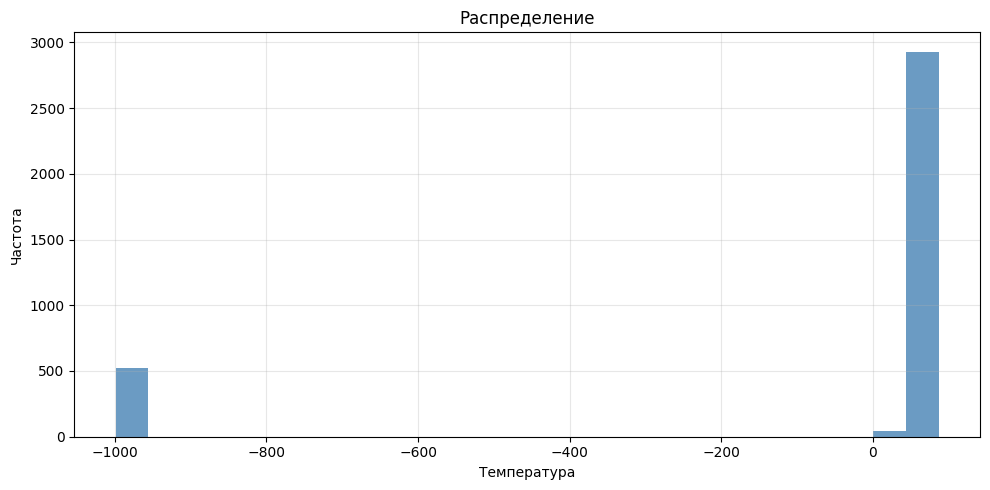

In [100]:
plt.figure(figsize=(10, 5))
plt.hist(train["temperature"], bins=25, color="steelblue", alpha=0.8)
plt.title("Распределение")
plt.xlabel("Температура")
plt.ylabel("Частота")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Теперь, посмотрим на распределение по классам.

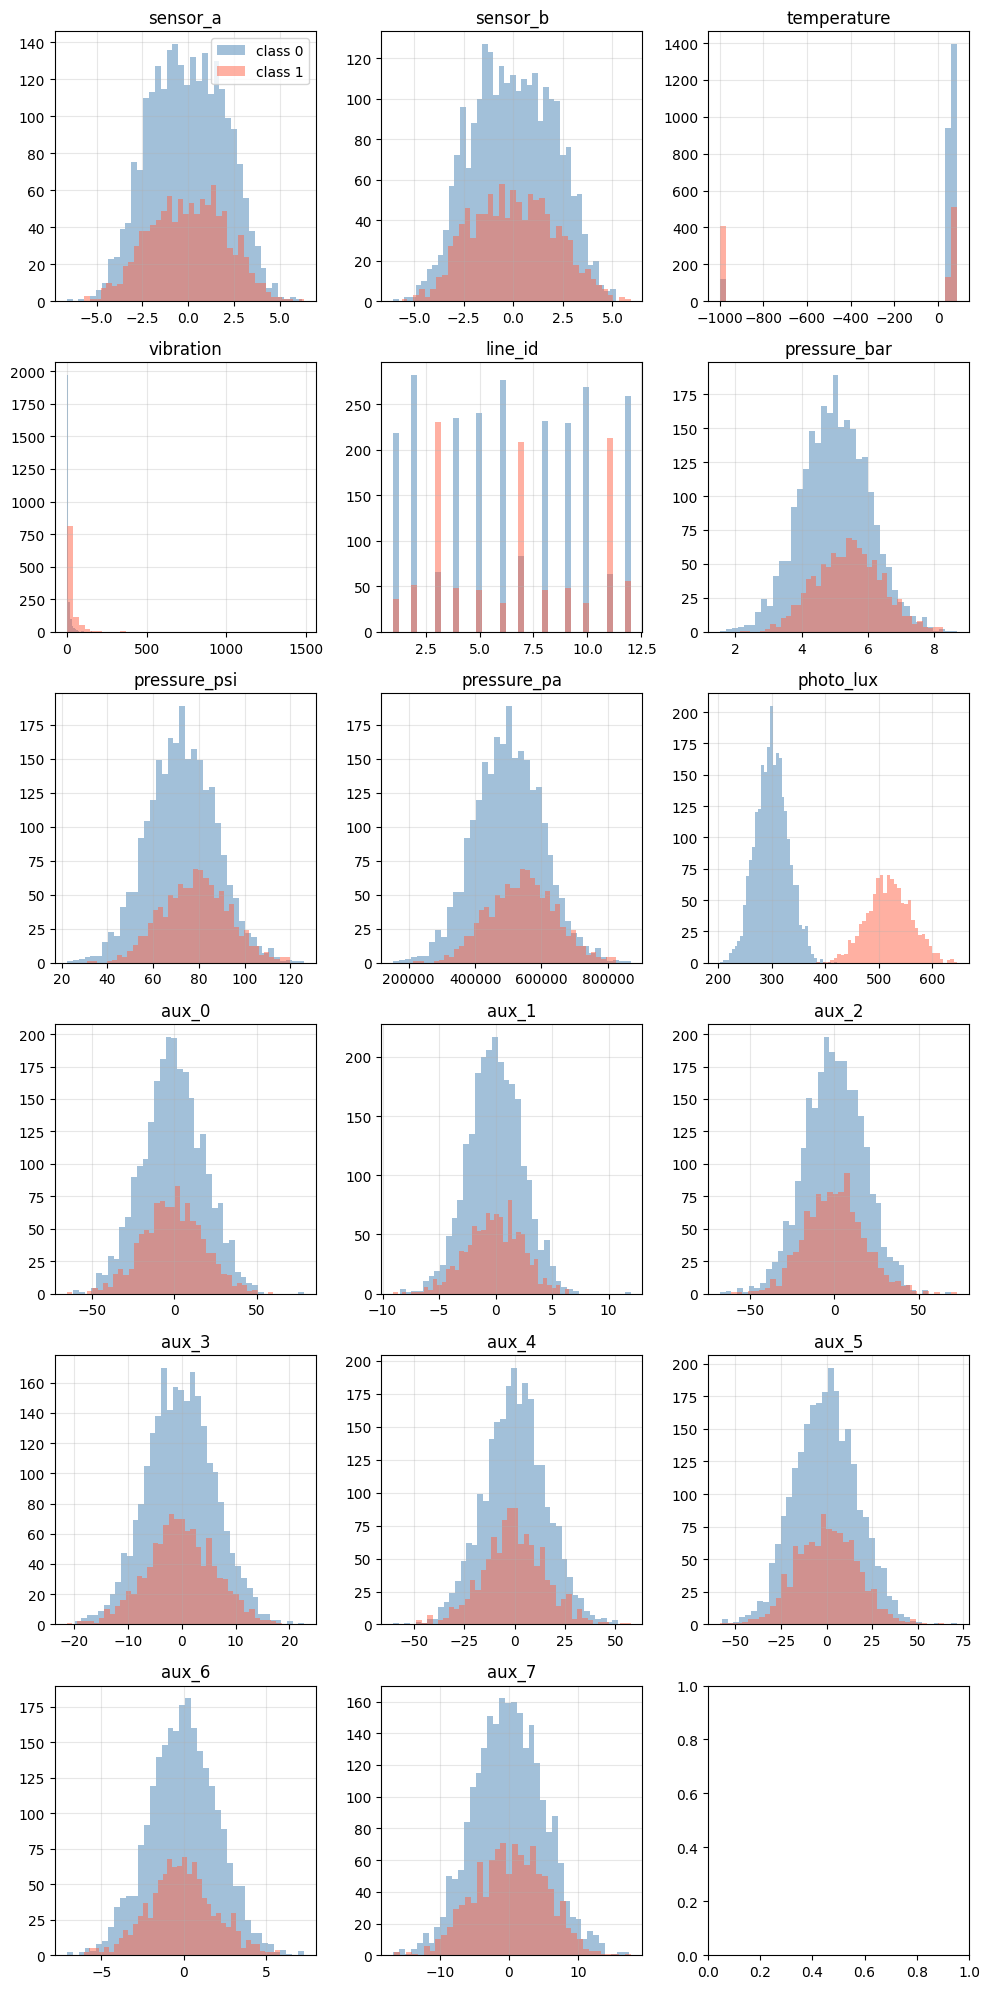

In [101]:
mask0 = train.defect == 0
mask1 = train.defect == 1

fig, axes = plt.subplots(6, 3, figsize=(10, 20))
for ax, col in zip(axes.flat, feature_cols):
    ax.hist(train.loc[mask0, col], bins=40, alpha=0.5, label="class 0", color="steelblue")
    ax.hist(train.loc[mask1, col], bins=40, alpha=0.5, label="class 1", color="tomato")
    ax.set_title(col)
    ax.grid(alpha=0.3)
axes[0, 0].legend()
plt.tight_layout()
plt.show()

**Наблюдение:** `photo_lux` практически разделяет детали с дефектом и без.

In [102]:
# Попробуем удалить эту фичу из выборок.
train = train.drop(columns=["photo_lux"])
test = test.drop(columns="photo_lux")

### **. Простая модель. Кросс-валидация.

In [103]:
X_train = train.drop(columns=["id", "defect"])
y_train = train.defect
X_test = test.drop(columns="id")

# Пайплайн: масштабирование + логистическая регрессия
pipe = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
)

# Стратифицированная 5-fold кросс-валидация
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc")

print(f"CV ROC-AUC: {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")
print(f"По фолдам:  {np.round(cv_scores, 3).tolist()}")

CV ROC-AUC: 0.799 ± 0.008
По фолдам:  [0.802, 0.792, 0.793, 0.813, 0.794]


In [104]:
# Обучаем на всём train
pipe.fit(X_train, y_train)

# Предсказываем вероятности на test
proba = pipe.predict_proba(X_test)[:, 1]

# Собираем сабмит
submission = pd.DataFrame({
    "id": test["id"],
    "defect": proba,
})

# Сохраняем
submission.to_csv("submission.csv", index=False)

print("Сабмит сохранён в submission.csv")
print(f"Строк: {len(submission)}")
submission.head()

Сабмит сохранён в submission.csv
Строк: 1500


,id,defect
0,100000,0.688996
1,100001,0.207327
2,100002,0.116851
3,100003,0.192844
4,100004,0.144076


**Санитарные проверки перед отправкой в Kaggle**

In [105]:
# 1. Число строк совпадает с test
assert len(submission) == len(test), "Число строк не совпадает с test.csv!"

# 2. Все id из test присутствуют в сабмите (и наоборот)
assert set(submission.id) == set(test.id), "id в сабмите не совпадают с id в test.csv!"

# 3. Нет дубликатов id
assert submission.id.is_unique, "В сабмите есть дублирующиеся id!"

# 4. Нет NaN в предсказаниях
assert submission.iloc[:, 1].notna().all(), "В предсказаниях есть NaN!"

print("Все проверки пройдены — сабмит готов к отправке.")

Все проверки пройдены — сабмит готов к отправке.


**Выгружаем сабмит из хранилища Google Colab к себе**

In [106]:
from google.colab import drive
drive.mount('/content/drive')

!cp /content/submission.csv /content/drive/MyDrive/ml-dafe-s1-hw1-submission.csv

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
